Boilerplate Code

In [1]:
#install if you dont already have the dependencies
!pip install numpy pandas scikit-learn ucimlrepo matplotlib seaborn joblib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import sys
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#neural network (multi-layer perceptron)
import copy
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss

from sklearn.model_selection import train_test_split, ParameterSampler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, average_precision_score, precision_recall_curve
import joblib
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data import (
    load_dataset,
    feature_types,
    split,
    make_preprocessor,
)
from src.corrupt import (
    inject_missing_mcar,
    inject_missing_mnar,
    flip_labels,
    perturb_features
)

split_seed = 42
experiment_seed = [42, 43, 44]

dataset_names = ["adult", "ai4i"]
corruption_rates = [0.0, 0.1, 0.2, 0.3, 0.4]
noise_scale = 1.0

# 60 / 20 / 20 split
validation_split = 0.25 
#output directories
results_dir = ROOT / "results" / "neural_network"
models_dir = ROOT / "models" / "neural_network"
results_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

certifications for downloading uci dataset

In [3]:
import socket
import os
import ssl
import urllib.request
import certifi

ssl_context = ssl.create_default_context(cafile=certifi.where())

opener = urllib.request.build_opener(
    urllib.request.HTTPSHandler(context=ssl_context)
)

urllib.request.install_opener(opener)

os.environ["SSL_CERT_FILE"] = certifi.where()
print(socket.gethostbyname("archive.ics.uci.edu"))

128.195.10.252


Load Data and create splits

In [4]:
clean_data = {}
split_sizes = []

for dataset_name in dataset_names:
    print(f"Loading dataset: {dataset_name}")
    X, y = load_dataset(dataset_name)

    # test split
    X_train_full, X_test, y_train_full, y_test = split(X, y, seed=split_seed)

    #val split
    X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=validation_split, stratify=y_train_full, random_state=split_seed)

    clean_data[dataset_name] = {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

    split_sizes.append({
        "dataset": dataset_name,
        "train_size": len(X_train),
        "val_size": len(X_val),
        "test_size": len(X_test)
    })

Loading dataset: adult
Loading dataset: ai4i


Neural Network Model

A multi-layer perceptron : fully connected hidden layers with ReLU, one sigmoid (logistic) output neuron for the probability of the positive class, trained with backpropagation and SGD with momentum. alpha is the L2 regularization penalty on the weights.

Unlike XGBoost, a neural network cannot take NaN as input, so every neural network uses mode="impute": missing numeric values are filled with the median and then standardized (normalizing the inputs speeds up training), and missing categories are filled with the most common value and then one-hot encoded. Adult already has missing values in workclass, occupation and native_country, so even the clean model fills in values.

Training stops early like the "cross validation termination procedure" from lecture 6 where we train one epoch at a time, check the weights on the validation set after each epoch, keep the best set of weights so far, and stop when validation average precision has not improved for 10 epochs. This is the same idea as XGBoost's early stopping on the validation set (max 200 epochs here instead of 1000 rounds). We do this ourselves with partial_fit because MLPClassifier(early_stopping=True) would carve its own validation set out of the training data instead of using ours.

In [6]:
max_epochs = 200
patience = 10

def make_nn_preprocessor(X_train):
    # dense output (one-hot encoding is sparse by default)
    return make_preprocessor(X_train, mode="impute").set_params(sparse_threshold=0)


def fit_model(params, X_train, y_train, X_val, y_val, seed):
    model = MLPClassifier(
        hidden_layer_sizes=params["hidden_layers"],
        activation="relu",
        solver="sgd",
        momentum=0.9,
        alpha=params["alpha"],                      # L2 regularization
        learning_rate_init=params["learning_rate"],
        batch_size=params["batch_size"],
        random_state=seed,                          # same seed -> same starting weights and batch order
    )

    history = {"loss": [], "val_loss": [], "val_average_precision": []}
    best_score = -np.inf
    best_model = None
    best_epoch = 0
    epochs_without_improvement = 0

    start_time = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        # one epoch = one forward + backward pass over every mini-batch of the training data
        model.partial_fit(X_train, y_train, classes=[0, 1])

        train_score = model.predict_proba(X_train)[:, 1]
        val_score = model.predict_proba(X_val)[:, 1]
        history["loss"].append(log_loss(y_train, train_score))
        history["val_loss"].append(log_loss(y_val, val_score))
        val_ap = average_precision_score(y_val, val_score)
        history["val_average_precision"].append(val_ap)

        # keep the best set of weights measured on validation
        if val_ap > best_score:
            best_score = val_ap
            best_model = copy.deepcopy(model)
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break
    training_seconds = time.perf_counter() - start_time
    return best_model, history, training_seconds, best_epoch


def predict_scores(model, X):
    return model.predict_proba(X)[:, 1]


def best_f1_threshold(y_true, y_score):
    # pick the threshold with the best F1 on validation instead of using 0.5
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_score)
    f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    return thresholds[np.argmax(f1s[:-1])]

Tune Hyperparameters Using Random Search

Try 15 random combinations and keep the one with the best validation average precision. Each candidate is scored on the validation set instead of 5-fold CV, because training a neural network 5 times per candidate would take much longer.

In [7]:
param_grid = {
    "hidden_layers": [(32,), (64,), (64, 32), (128, 64), (64, 32, 16)],
    "learning_rate": [0.005, 0.01, 0.05],
    "alpha": [0.0, 0.0001, 0.001, 0.01],
    "batch_size": [64, 256],
}
n_iter = 15

best_params = {}
search_results = []

for dataset_name in dataset_names:
    data = clean_data[dataset_name]

    # preprocess once so every candidate gets the same inputs
    preprocessor = make_nn_preprocessor(data["X_train"])
    X_train_preprocessed = preprocessor.fit_transform(data["X_train"])
    X_val_preprocessed = preprocessor.transform(data["X_val"])

    candidates = []
    for params in ParameterSampler(param_grid, n_iter=n_iter, random_state=split_seed):
        model, history, training_seconds, best_epoch = fit_model(
            params, X_train_preprocessed, data["y_train"], X_val_preprocessed, data["y_val"], seed=split_seed)
        score = average_precision_score(data["y_val"], predict_scores(model, X_val_preprocessed))
        candidates.append({**params, "val_average_precision": score, "best_epoch": best_epoch})
        print(f"{dataset_name}: {params} -> val AP {score:.4f} (best epoch {best_epoch}, {training_seconds:.1f}s)")

    candidates = pd.DataFrame(candidates).sort_values("val_average_precision", ascending=False)
    best = candidates.iloc[0]
    best_params[dataset_name] = {key: best[key] for key in param_grid}
    candidates.to_csv(results_dir / f"search_{dataset_name}.csv", index=False)

    search_results.append({
        "dataset": dataset_name,
        "best_score": best["val_average_precision"],
        "best_params": best_params[dataset_name],
    })

pd.DataFrame(search_results)

adult: {'learning_rate': 0.05, 'hidden_layers': (64, 32, 16), 'batch_size': 64, 'alpha': 0.0001} -> val AP 0.7973 (best epoch 4, 0.9s)
adult: {'learning_rate': 0.05, 'hidden_layers': (32,), 'batch_size': 256, 'alpha': 0.0001} -> val AP 0.7967 (best epoch 9, 0.4s)
adult: {'learning_rate': 0.01, 'hidden_layers': (64,), 'batch_size': 64, 'alpha': 0.0} -> val AP 0.7985 (best epoch 16, 1.2s)
adult: {'learning_rate': 0.01, 'hidden_layers': (128, 64), 'batch_size': 256, 'alpha': 0.0001} -> val AP 0.7986 (best epoch 23, 1.7s)
adult: {'learning_rate': 0.05, 'hidden_layers': (128, 64), 'batch_size': 256, 'alpha': 0.0} -> val AP 0.7987 (best epoch 9, 1.0s)
adult: {'learning_rate': 0.01, 'hidden_layers': (64,), 'batch_size': 64, 'alpha': 0.001} -> val AP 0.7986 (best epoch 31, 1.9s)
adult: {'learning_rate': 0.01, 'hidden_layers': (64, 32, 16), 'batch_size': 64, 'alpha': 0.001} -> val AP 0.7976 (best epoch 15, 1.6s)
adult: {'learning_rate': 0.01, 'hidden_layers': (128, 64), 'batch_size': 64, 'alpha

,dataset,best_score,best_params
0,adult,0.799740,"{'hidden_layers': (128, 64), 'learning_rate': ..."
1,ai4i,0.746494,"{'hidden_layers': (32,), 'learning_rate': 0.05..."


Train Neural Network

In [8]:
normal_models = {}
normal_histories = {}
normal_preprocessors = {}
normal_thresholds = {}
training_times = {}
best_epochs = {}
for dataset_name in dataset_names:
    print(f"Training neural network on dataset: {dataset_name}")
    data = clean_data[dataset_name]
    preprocessor = make_nn_preprocessor(data["X_train"])

    X_train_preprocessed = preprocessor.fit_transform(data["X_train"])
    X_val_preprocessed = preprocessor.transform(data["X_val"])

    normal_preprocessors[dataset_name] = preprocessor

    for seed in experiment_seed:
        # max epochs is 200, early stopping is 10 epochs without improvement
        model, history, training_seconds, best_epoch = fit_model(
            best_params[dataset_name], X_train_preprocessed, data["y_train"], X_val_preprocessed, data["y_val"], seed=seed)

        #log training time and save model
        training_times[(dataset_name, seed)] = training_seconds
        best_epochs[(dataset_name, seed)] = best_epoch
        normal_models[(dataset_name, seed)] = model
        normal_histories[(dataset_name, seed)] = history

        normal_thresholds[(dataset_name, seed)] = best_f1_threshold(data["y_val"], predict_scores(model, X_val_preprocessed))
        print(f"Training time for {dataset_name} with seed {seed}: {training_seconds:.2f} seconds and best epoch: {best_epoch} and best threshold: {normal_thresholds[(dataset_name, seed)]:.2f}")

Training neural network on dataset: adult
Training time for adult with seed 42: 1.30 seconds and best epoch: 5 and best threshold: 0.32
Training time for adult with seed 43: 1.43 seconds and best epoch: 7 and best threshold: 0.40
Training time for adult with seed 44: 1.43 seconds and best epoch: 7 and best threshold: 0.44
Training neural network on dataset: ai4i
Training time for ai4i with seed 42: 0.97 seconds and best epoch: 105 and best threshold: 0.42
Training time for ai4i with seed 43: 0.69 seconds and best epoch: 70 and best threshold: 0.30
Training time for ai4i with seed 44: 0.52 seconds and best epoch: 53 and best threshold: 0.43


Training curves

Training and validation loss per epoch (first seed). The dotted line marks the epoch whose weights were kept.

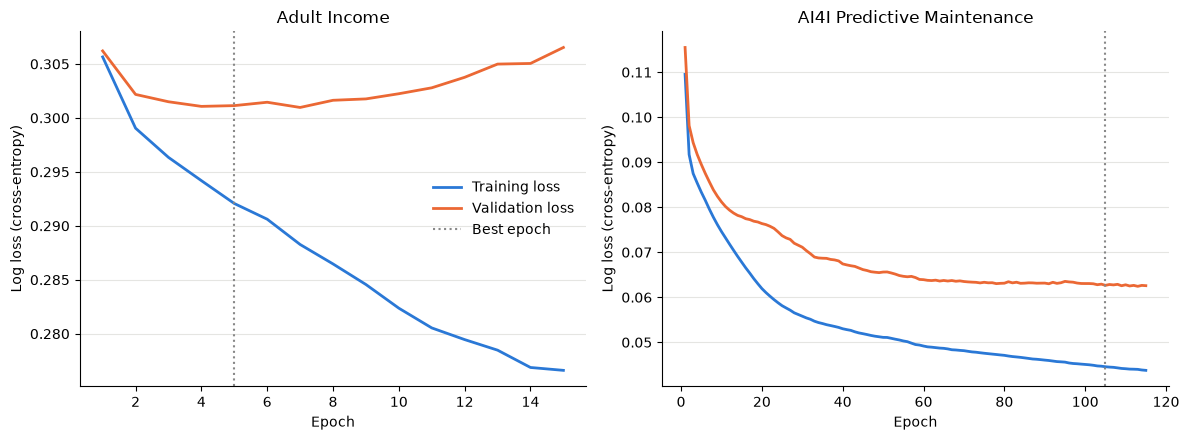

In [9]:
titles = {"adult": "Adult Income", "ai4i": "AI4I Predictive Maintenance"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, dataset_name in zip(axes, dataset_names):
    history = normal_histories[(dataset_name, experiment_seed[0])]
    epochs = range(1, len(history["loss"]) + 1)
    ax.plot(epochs, history["loss"], color="#2a78d6", linewidth=2, label="Training loss")
    ax.plot(epochs, history["val_loss"], color="#eb6834", linewidth=2, label="Validation loss")
    ax.axvline(best_epochs[(dataset_name, experiment_seed[0])], color="#888888", linestyle=":", linewidth=1.5, label="Best epoch")
    ax.set_title(titles[dataset_name])
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Log loss (cross-entropy)")
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(results_dir / "training_curves.png", dpi=150)
plt.show()

Validation

In [10]:
normal_val_metrics = []

for dataset_name in dataset_names:
    data = clean_data[dataset_name]
    preprocessor = normal_preprocessors[dataset_name]

    X_train_preprocessed = preprocessor.transform(data["X_train"])
    X_val_preprocessed = preprocessor.transform(data["X_val"])
    y_val = data["y_val"]

    for seed in experiment_seed:
        model = normal_models[(dataset_name, seed)]

        y_score = predict_scores(model, X_val_preprocessed)
        threshold = normal_thresholds[(dataset_name, seed)]
        y_train_score = predict_scores(model, X_train_preprocessed)
        y_pred = (y_score >= threshold).astype(int)

        normal_val_metrics.append({
            "dataset": dataset_name,
            "seed": seed,
            "threshold": threshold,
            "accuracy": accuracy_score(y_val, y_pred),
            "precision": precision_score(y_val, y_pred, zero_division=0),
            "recall": recall_score(y_val, y_pred, zero_division=0),
            "f1": f1_score(y_val, y_pred, zero_division=0),
            "average_precision": average_precision_score(y_val, y_score),
            # training score, to compare training vs validation for over/underfitting
            "train_average_precision": average_precision_score(data["y_train"], y_train_score),
            "best_epoch": best_epochs[(dataset_name, seed)],
            "training_seconds": training_times[(dataset_name, seed)],
        })

normal_val_df = pd.DataFrame(normal_val_metrics)
normal_val_df.round(4)

,dataset,seed,threshold,accuracy,precision,recall,f1,average_precision,train_average_precision,best_epoch,training_seconds
0,adult,42,0.3162,0.8499,0.6537,0.7933,0.7168,0.7997,0.8063,5,1.2995
1,adult,43,0.3975,0.8608,0.7056,0.7177,0.7116,0.7990,0.8096,7,1.4342
2,adult,44,0.4414,0.8522,0.6632,0.7772,0.7157,0.7937,0.8078,7,1.4308
3,ai4i,42,0.4172,0.9845,0.8627,0.6471,0.7395,0.7465,0.8473,105,0.9686
4,ai4i,43,0.2975,0.9805,0.7302,0.6765,0.7023,0.7147,0.8106,70,0.6875
5,ai4i,44,0.4340,0.9825,0.7895,0.6618,0.7200,0.7324,0.8195,53,0.5219


Test

In [11]:
normal_test_metrics = []

for dataset_name in dataset_names:
    data = clean_data[dataset_name]
    preprocessor = normal_preprocessors[dataset_name]

    # Apply the existing preprocessing; do not fit it again.
    X_test_preprocessed = preprocessor.transform(data["X_test"])
    y_test = data["y_test"]

    for seed in experiment_seed:
        model = normal_models[(dataset_name, seed)]

        y_score = predict_scores(model, X_test_preprocessed)
        threshold = normal_thresholds[(dataset_name, seed)]
        y_pred = (y_score >= threshold).astype(int)

        normal_test_metrics.append({
            "dataset": dataset_name,
            "seed": seed,
            "threshold": threshold,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred, zero_division=0),
            "f1": f1_score(y_test, y_pred, zero_division=0),
            "average_precision": average_precision_score(y_test, y_score),
            "hyperparameters": best_params[dataset_name],
        })

    # save one model per dataset for the web demo (preprocessing + model + threshold)
    joblib.dump({
        "preprocessor": preprocessor,
        "model": normal_models[(dataset_name, experiment_seed[0])],
        "threshold": normal_thresholds[(dataset_name, experiment_seed[0])],
    }, models_dir / f"{dataset_name}_clean.joblib")

normal_test_df = pd.DataFrame(normal_test_metrics)

#save results
clean_results_dir = results_dir / "clean"
clean_results_dir.mkdir(parents=True, exist_ok=True)
normal_val_df.to_csv(clean_results_dir / "validation.csv", index=False)
normal_test_df.to_csv(clean_results_dir / "test.csv", index=False)
normal_test_df.round(4)

,dataset,seed,threshold,accuracy,precision,recall,f1,average_precision,hyperparameters
0,adult,42,0.3162,0.8421,0.6356,0.7974,0.7074,0.7963,"{'hidden_layers': (128, 64), 'learning_rate': ..."
1,adult,43,0.3975,0.8576,0.6938,0.7253,0.7092,0.7974,"{'hidden_layers': (128, 64), 'learning_rate': ..."
2,adult,44,0.4414,0.8454,0.6480,0.7757,0.7061,0.7959,"{'hidden_layers': (128, 64), 'learning_rate': ..."
3,ai4i,42,0.4172,0.9750,0.6731,0.5147,0.5833,0.6879,"{'hidden_layers': (32,), 'learning_rate': 0.05..."
4,ai4i,43,0.2975,0.9745,0.6269,0.6176,0.6222,0.6986,"{'hidden_layers': (32,), 'learning_rate': 0.05..."
5,ai4i,44,0.4340,0.9795,0.7143,0.6618,0.6870,0.7219,"{'hidden_layers': (32,), 'learning_rate': 0.05..."


On clean data, the neural network reaches a mean test average precision of 0.797 on Adult and 0.703 on AI4I, below XGBoost (0.853 and 0.806). Adult results are stable across seeds. AI4I varies more (F1 0.58–0.69) because only 3.4% of its machines fail.

Corrupted data

Same corruption setup, rates and seeds as the XGBoost notebook. The neural network always fills in missing values first, so `mcar` here matches `mcar_imputed` in the XGBoost notebook (there is no separate `mcar_imputed` run). Hyperparameters stay the same as the clean model.

In [12]:
corruption_rates = [0.1, 0.2, 0.3, 0.4]
corruption_seed = 42

# mcar = missing values (filled in before the network sees them), noise = inaccurate measurements,
# label_flip = false labels
# mcar_test = same as mcar, but the test set has missing values too
corruption_types = ["mcar", "mcar_test", "noise", "label_flip"]

corrupted_models = {}
corrupted_preprocessors = {}
corrupted_thresholds = {}
corrupted_training_times = {}
corrupted_val_metrics = []
corrupted_test_metrics = []
missingness = []

for corruption_type in corruption_types:
    corrupted_results_dir = results_dir / corruption_type
    corrupted_results_dir.mkdir(parents=True, exist_ok=True)

    for dataset_name in dataset_names:
        for missing_rate in corruption_rates:
            print(f"Training neural network on {dataset_name} with {missing_rate:.0%} {corruption_type}")

            # use the same splits as the normal models
            data = clean_data[dataset_name].copy()
            train_rng = np.random.default_rng(corruption_seed)
            val_rng = np.random.default_rng(corruption_seed + 1)
            test_rng = np.random.default_rng(corruption_seed + 2)

            # corrupt the training and validation sets, the test set stays clean (except for mcar_test)
            if corruption_type in ["mcar", "mcar_test"]:
                data["X_train"] = inject_missing_mcar(data["X_train"], missing_rate, rng=train_rng)
                data["X_val"] = inject_missing_mcar(data["X_val"], missing_rate, rng=val_rng)
                if corruption_type == "mcar_test":
                    data["X_test"] = inject_missing_mcar(data["X_test"], missing_rate, rng=test_rng)
            elif corruption_type == "noise":
                data["X_train"] = perturb_features(data["X_train"], missing_rate, rng=train_rng, noise_scale=noise_scale)
                data["X_val"] = perturb_features(data["X_val"], missing_rate, rng=val_rng, noise_scale=noise_scale)
            elif corruption_type == "label_flip":
                data["y_train"] = flip_labels(data["y_train"], missing_rate, rng=train_rng)
                data["y_val"] = flip_labels(data["y_val"], missing_rate, rng=val_rng)

            #check missingness
            missingness.append({
                "corruption_type": corruption_type,
                "dataset": dataset_name,
                "missing_rate": missing_rate,
                "corruption_seed": corruption_seed,
                "training_missing_pct": 100 * data["X_train"].isna().to_numpy().mean(),
                "validation_missing_pct": 100 * data["X_val"].isna().to_numpy().mean(),
                "test_missing_pct": 100 * data["X_test"].isna().to_numpy().mean(),
            })

            # fill in missing values, then scale / one-hot encode (fit on the corrupted training set)
            preprocessor = make_nn_preprocessor(data["X_train"])
            X_train_preprocessed = preprocessor.fit_transform(data["X_train"])
            X_val_preprocessed = preprocessor.transform(data["X_val"])
            # Apply the existing preprocessing; do not fit it again.
            X_test_preprocessed = preprocessor.transform(data["X_test"])

            corrupted_preprocessors[(corruption_type, dataset_name, missing_rate)] = preprocessor

            for seed in experiment_seed:
                key = (corruption_type, dataset_name, missing_rate, seed)
                # same hyperparameters as the normal models
                model, history, training_seconds, best_epoch = fit_model(
                    best_params[dataset_name], X_train_preprocessed, data["y_train"], X_val_preprocessed, data["y_val"], seed=seed)

                #log training time and save model
                corrupted_training_times[key] = training_seconds
                corrupted_models[key] = (model, best_epoch)

                # pick the threshold with the best F1 on validation, using the clean validation labels
                # (with flipped labels, the best-F1 threshold is "predict everything positive")
                corrupted_thresholds[key] = best_f1_threshold(clean_data[dataset_name]["y_val"], predict_scores(model, X_val_preprocessed))
                print(f"Training time for {dataset_name} with {missing_rate:.0%} {corruption_type} and seed {seed}: {training_seconds:.2f} seconds and best epoch: {best_epoch}")

            # Validation and Test
            for X_preprocessed, y_true, metrics_list in [(X_val_preprocessed, data["y_val"], corrupted_val_metrics),
                                                        (X_test_preprocessed, data["y_test"], corrupted_test_metrics)]:
                for seed in experiment_seed:
                    key = (corruption_type, dataset_name, missing_rate, seed)
                    model, best_epoch = corrupted_models[key]
                    threshold = corrupted_thresholds[key]

                    y_score = predict_scores(model, X_preprocessed)
                    y_pred = (y_score >= threshold).astype(int)

                    metrics_list.append({
                        "corruption_type": corruption_type,
                        "dataset": dataset_name,
                        "missing_rate": missing_rate,
                        "corruption_seed": corruption_seed,
                        "seed": seed,
                        "threshold": threshold,
                        "accuracy": accuracy_score(y_true, y_pred),
                        "precision": precision_score(y_true, y_pred, zero_division=0),
                        "recall": recall_score(y_true, y_pred, zero_division=0),
                        "f1": f1_score(y_true, y_pred, zero_division=0),
                        "average_precision": average_precision_score(y_true, y_score),
                        "best_epoch": best_epoch,
                        "training_seconds": corrupted_training_times[key],
                        "hyperparameters": best_params[dataset_name],
                    })

        #save results after each corruption type and dataset
        corrupted_val_df = pd.DataFrame(corrupted_val_metrics)
        corrupted_test_df = pd.DataFrame(corrupted_test_metrics)
        corrupted_val_df[corrupted_val_df.corruption_type == corruption_type].to_csv(corrupted_results_dir / "validation.csv", index=False)
        corrupted_test_df[corrupted_test_df.corruption_type == corruption_type].to_csv(corrupted_results_dir / "test.csv", index=False)
        pd.DataFrame(missingness).to_csv(results_dir / "missingness.csv", index=False)

#average test performance across the three seeds
test_summary = corrupted_test_df.groupby(["corruption_type", "dataset", "missing_rate"])[
    ["accuracy", "precision", "recall", "f1", "average_precision"]
].agg(["mean", "std"])

test_summary.to_csv(results_dir / "test_summary.csv")
display(test_summary.round(4))

Training neural network on adult with 10% mcar
Training time for adult with 10% mcar and seed 42: 1.44 seconds and best epoch: 7
Training time for adult with 10% mcar and seed 43: 1.34 seconds and best epoch: 6
Training time for adult with 10% mcar and seed 44: 1.34 seconds and best epoch: 6
Training neural network on adult with 20% mcar
Training time for adult with 20% mcar and seed 42: 1.34 seconds and best epoch: 6
Training time for adult with 20% mcar and seed 43: 1.44 seconds and best epoch: 7
Training time for adult with 20% mcar and seed 44: 1.43 seconds and best epoch: 7
Training neural network on adult with 30% mcar
Training time for adult with 30% mcar and seed 42: 1.76 seconds and best epoch: 11
Training time for adult with 30% mcar and seed 43: 1.80 seconds and best epoch: 11
Training time for adult with 30% mcar and seed 44: 1.55 seconds and best epoch: 8
Training neural network on adult with 40% mcar
Training time for adult with 40% mcar and seed 42: 1.69 seconds and best

accuracy         precision          \
                                         mean     std      mean     std   
corruption_type dataset missing_rate                                      
label_flip      adult   0.1            0.8424  0.0020    0.6398  0.0049   
                        0.2            0.8466  0.0068    0.6576  0.0261   
                        0.3            0.8376  0.0059    0.6321  0.0137   
                        0.4            0.8219  0.0100    0.6018  0.0211   
                ai4i    0.1            0.9758  0.0020    0.7006  0.0365   
                        0.2            0.9725  0.0026    0.6978  0.0822   
                        0.3            0.9683  0.0046    0.5534  0.0842   
                        0.4            0.8563  0.1445    0.1324  0.1124   
mcar            adult   0.1            0.8415  0.0069    0.6366  0.0192   
                        0.2            0.8376  0.0020    0.6253  0.0048   
                        0.3            0.8454  0.0106    0.6476  0.0308   
                        0.4            0.8310  0.0143    0.6128  0.0304   
                ai4i    0.1            0.9727  0.0020    0.6266  0.0559   
                        0.2            0.9713  0.0037    0.5877  0.0675   
                        0.3            0.9698  0.0015    0.5626  0.0367   
                        0.4            0.9697  0.0030    0.6384  0.1191   
mcar_test       adult   0.1            0.8350  0.0075    0.6258  0.0210   
                        0.2            0.8219  0.0041    0.5975  0.0078   
                        0.3            0.8162  0.0140    0.5950  0.0357   
                        0.4            0.7831  0.0106    0.5331  0.0177   
                ai4i    0.1            0.9707  0.0025    0.5952  0.0596   
                        0.2            0.9667  0.0030    0.5190  0.0539   
                        0.3            0.9693  0.0003    0.5740  0.0160   
                        0.4            0.9688  0.0026    0.5988  0.0859   
noise           adult   0.1            0.8460  0.0036    0.6541  0.0149   
                        0.2            0.8429  0.0025    0.6489  0.0073   
                        0.3            0.8347  0.0045    0.6268  0.0155   
                        0.4            0.8304  0.0061    0.6167  0.0144   
                ai4i    0.1            0.9698  0.0024    0.6015  0.0573   
                        0.2            0.9623  0.0053    0.4651  0.0579   
                        0.3            0.9663  0.0008    0.5058  0.0142   
                        0.4            0.9658  0.0016    0.5002  0.0279   

                                      recall              f1          \
                                        mean     std    mean     std   
corruption_type dataset missing_rate                                   
label_flip      adult   0.1           0.7818  0.0031  0.7037  0.0021   
                        0.2           0.7547  0.0356  0.7019  0.0011   
                        0.3           0.7712  0.0076  0.6946  0.0065   
                        0.4           0.7608  0.0090  0.6718  0.0104   
                ai4i    0.1           0.5049  0.0473  0.5863  0.0408   
                        0.2           0.3627  0.1428  0.4605  0.1256   
                        0.3           0.4510  0.0473  0.4927  0.0354   
                        0.4           0.3824  0.3164  0.1693  0.1317   
mcar            adult   0.1           0.7902  0.0182  0.7048  0.0044   
                        0.2           0.8026  0.0052  0.7029  0.0019   
                        0.3           0.7844  0.0316  0.7086  0.0061   
                        0.4           0.8088  0.0229  0.6966  0.0117   
                ai4i    0.1           0.5049  0.0370  0.5568  0.0005   
                        0.2           0.5735  0.1176  0.5737  0.0572   
                        0.3           0.5392  0.0612  0.5477  0.0164   
                        0.4           0.3382  0.1307  0.4217  0.0742   
mcar_test       adult   0.1           0.776

Test performance as the training data gets worse

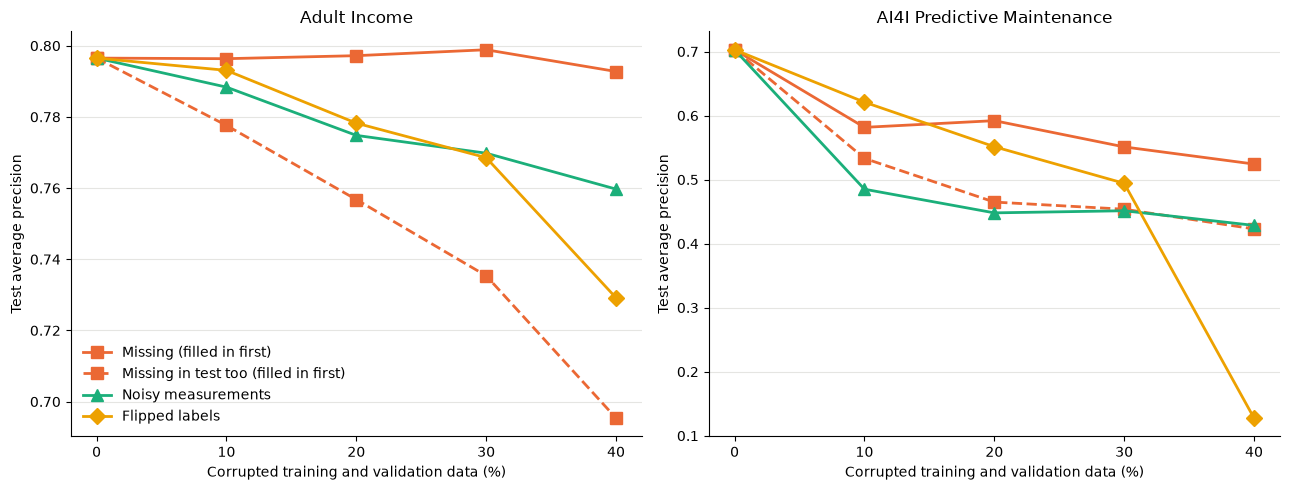

In [13]:
# average test AP over the three seeds, for each corruption type and rate
baseline_ap = normal_test_df.groupby("dataset")["average_precision"].mean()
plot_df = corrupted_test_df.groupby(["corruption_type", "dataset", "missing_rate"])["average_precision"].mean().reset_index()

labels = {"mcar": "Missing (filled in first)", "mcar_test": "Missing in test too (filled in first)",
          "noise": "Noisy measurements", "label_flip": "Flipped labels"}
colors = {"mcar": "#eb6834", "mcar_test": "#eb6834", "noise": "#1baf7a", "label_flip": "#eda100"}
markers = {"mcar": "s", "mcar_test": "s", "noise": "^", "label_flip": "D"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, dataset_name in zip(axes, dataset_names):
    for corruption_type in corruption_types:
        rows = plot_df[(plot_df.corruption_type == corruption_type) & (plot_df.dataset == dataset_name)]
        # every line starts at the clean baseline (0% corrupted)
        x = [0] + list(100 * rows.missing_rate)
        y = [baseline_ap[dataset_name]] + list(rows.average_precision)
        ax.plot(x, y, color=colors[corruption_type], marker=markers[corruption_type],
                markersize=8, linewidth=2, label=labels[corruption_type],
                linestyle="--" if corruption_type.endswith("_test") else "-")
    ax.set_title(titles[dataset_name])
    ax.set_xlabel("Corrupted training and validation data (%)")
    ax.set_ylabel("Test average precision")
    ax.set_xticks([0, 10, 20, 30, 40])
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(results_dir / "test_ap_vs_corruption.png", dpi=150)
plt.show()

Neural network vs. XGBoost:

In [ ]:
xgboost_dir = ROOT / "results" / "xgboost"

if (xgboost_dir / "clean" / "test.csv").exists():
    # (model name, results folder, corruption type in that folder, label for the comparison)
    runs = [("Neural network", results_dir, "mcar", "mcar"),
            ("XGBoost (handles NaN)", xgboost_dir, "mcar", "mcar"),
            ("XGBoost (filled in first)", xgboost_dir, "mcar_imputed", "mcar"),
            ("Neural network", results_dir, "mcar_test", "mcar_test"),
            ("XGBoost (handles NaN)", xgboost_dir, "mcar_test", "mcar_test"),
            ("XGBoost (filled in first)", xgboost_dir, "mcar_imputed_test", "mcar_test"),
            ("Neural network", results_dir, "noise", "noise"),
            ("XGBoost (handles NaN)", xgboost_dir, "noise", "noise"),
            ("Neural network", results_dir, "label_flip", "label_flip"),
            ("XGBoost (handles NaN)", xgboost_dir, "label_flip", "label_flip")]

    comparison = []
    for model_name, folder, corruption_type, label in runs:
        path = folder / corruption_type / "test.csv"
        if not path.exists():
            continue
        df = pd.read_csv(path).assign(model=model_name, corruption=label)
        comparison.append(df)
    # clean baselines (0% corrupted)
    for model_name, path in [("Neural network", results_dir / "clean" / "test.csv"),
                             ("XGBoost (handles NaN)", xgboost_dir / "clean" / "test.csv"),
                             ("XGBoost (filled in first)", xgboost_dir / "clean" / "test_imputed.csv")]:
        if path.exists():
            comparison.append(pd.read_csv(path).assign(model=model_name, corruption="clean", missing_rate=0.0))

    comparison = pd.concat(comparison)
    comparison_table = comparison.pivot_table(index=["dataset", "corruption", "missing_rate"], columns="model",
                                              values="average_precision", aggfunc="mean")
    comparison_table.to_csv(results_dir / "comparison_with_xgboost.csv")
    display(comparison_table.round(4))
else:
    print("Run the XGBoost notebook first to compare.")

model                            Neural network  XGBoost (filled in first)  \
dataset corruption missing_rate                                              
adult   clean      0.0                   0.7965                        NaN   
        label_flip 0.1                   0.7931                        NaN   
                   0.2                   0.7782                        NaN   
                   0.3                   0.7685                        NaN   
                   0.4                   0.7292                        NaN   
        mcar       0.1                   0.7964                     0.8489   
                   0.2                   0.7972                     0.8496   
                   0.3                   0.7989                     0.8481   
                   0.4                   0.7928                     0.8458   
        mcar_test  0.1                   0.7776                        NaN   
                   0.2                   0.7568                        NaN   
                   0.3                   0.7354                        NaN   
                   0.4                   0.6954                        NaN   
        noise      0.1                   0.7884                        NaN   
                   0.2                   0.7748                        NaN   
                   0.3                   0.7698                        NaN   
                   0.4                   0.7597                        NaN   
ai4i    clean      0.0                   0.7028                        NaN   
        label_flip 0.1                   0.6210                        NaN   
                   0.2                   0.5514                        NaN   
                   0.3                   0.4942                        NaN   
                   0.4                   0.1276                        NaN   
        mcar       0.1                   0.5816                     0.7720   
                   0.2                   0.5921                     0.7236   
                   0.3                   0.5511                     0.6546   
                   0.4                   0.5243                     0.5965   
        mcar_test  0.1                   0.5332                        NaN   
                   0.2                   0.4649                        NaN   
                   0.3                   0.4538                        NaN   
                   0.4                   0.4230                        NaN   
        noise      0.1                   0.4850                        NaN   
                   0.2                   0.4481                        NaN   
                   0.3                   0.4514                        NaN   
                   0.4                   0.4285                        NaN   

model                            XGBoost (handles NaN)  
dataset corruption missing_rate                         
adult   clean      0.0                          0.8530  
        label_flip 0.1                          0.8413  
                   0.2                          0.8282  
                   0.3                          0.8059  
                   0.4                          0.7346  
        mcar       0.1                          0.8511  
                   0.2                          0.8506  
                   0.3                          0.8492  
                   0.4                          0.8447  
        mcar_test  0.1                             NaN  
                   0.2                             NaN  
                   0.3                             NaN  
                   0.4                             NaN  
        noise      0.1                          0.8418  
                   0.2                          0.8327  
                   0.3                          0.8215  
                   0.4                          0.8177  
ai4i    clean      0.0                          0.8059  
        label_flip 0.1                          0.6